In [ ]:
!pip install -q openpyxl scikit-learn xgboost catboost lightgbm scipy statsmodels kagglehub

import kagglehub
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Load and clean — same as before, fast (seconds)
path = kagglehub.dataset_download("sumathisanthosh/gestational-diabetes-mellitus-gdm-data-set")
df = pd.read_excel(os.path.join(path, "Gestational Diabetic Dat Set.xlsx"))
df = df.drop(columns=['Case Number', 'OGTT'])
label_column = 'Class Label(GDM /Non GDM)'

X = df.drop(columns=[label_column])
y = df[label_column]
X_raw = X.copy()
y_raw = y.copy()
feat_name_list = X.columns.tolist()
cols_to_impute = ['BMI', 'HDL', 'Sys BP']

# LOCKED final feature set — no need to rerun mealpy/PSO/GA/GWO/DFO to get this again
mmcfs_stable_core = ['BMI', 'Prediabetes', 'PCOS', 'Gestation in previous Pregnancy',
    'Sys BP', 'Family History', 'Age', 'unexplained prenetal loss',
    'Large Child or Birth Default', 'Sedentary Lifestyle']

# Standard imputation + scaling for full-feature baseline use
X_imputed = X.copy()
for col in cols_to_impute:
    X_imputed[col] = X_imputed[col].fillna(X_imputed[col].median())
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Reusable evaluation harness
def evaluate_model(model, X, y, model_name="Model", n_splits=5, random_state=42):
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
    from sklearn.model_selection import cross_validate
    results = cross_validate(model, X, y, cv=cv, scoring=scoring)
    print(f"\n=== {model_name} ===")
    summary = {}
    for metric in scoring:
        scores = results[f'test_{metric}']
        summary[metric] = (scores.mean(), scores.std())
        print(f"{metric.capitalize():10s}: {scores.mean():.4f} +/- {scores.std():.4f}")
    return summary

print("Setup complete. Ready for journal-stage experiments.")
print(f"Full features: {len(feat_name_list)} | MMCFS features: {len(mmcfs_stable_core)}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 6.4 MB/s eta 0:00:00


100%|██████████| 194k/194k [00:00<00:00, 50.9MB/s]

Extracting files...


Setup complete. Ready for journal-stage experiments.
Full features: 14 | MMCFS features: 10


**1. Wilcoxon Signed-Rank Test (paired, per-fold, MMCFS vs. Full)**

**2. McNemar's Test (prediction contingency, out-of-fold predictions)**

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from scipy.stats import wilcoxon
import numpy as np
import pandas as pd

RF_PARAMS = {
    "n_estimators": 300,
    "random_state": 42,
    "n_jobs": -1
}

def repeated_cv(X, y, features, repeats=10, n_splits=5):
    rows = []
    for r in range(repeats):
        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42+r)

        for fold, (tr, te) in enumerate(cv.split(X, y), 1):
            Xtr, Xte = X.iloc[tr][features].copy(), X.iloc[te][features].copy()
            ytr, yte = y.iloc[tr], y.iloc[te]

            for c in [c for c in cols_to_impute if c in features]:
                med = Xtr[c].median()
                Xtr[c] = Xtr[c].fillna(med)
                Xte[c] = Xte[c].fillna(med)

            sc = StandardScaler()
            Xtr, Xte = sc.fit_transform(Xtr), sc.transform(Xte)

            model = RandomForestClassifier(**RF_PARAMS)
            model.fit(Xtr, ytr)
            pred = model.predict(Xte)
            prob = model.predict_proba(Xte)[:, 1]

            rows.append([
                r+1, fold,
                accuracy_score(yte, pred),
                f1_score(yte, pred),
                roc_auc_score(yte, prob)
            ])

    return pd.DataFrame(rows, columns=["Repeat","Fold","Accuracy","F1","AUC"])

full_res = repeated_cv(X_raw, y_raw, feat_name_list)
mmcfs_res = repeated_cv(X_raw, y_raw, mmcfs_stable_core)

print("FULL FEATURES")
print(full_res[["Accuracy","F1","AUC"]].agg(["mean","std"]))

print("\nMMCFS")
print(mmcfs_res[["Accuracy","F1","AUC"]].agg(["mean","std"]))

for m in ["Accuracy","F1","AUC"]:
    stat, p = wilcoxon(full_res[m], mmcfs_res[m])
    print(f"\nWilcoxon {m}: statistic={stat:.4f}, p={p:.4f}")

FULL FEATURES
      Accuracy        F1       AUC
mean  0.971688  0.964039  0.998345
std   0.004829  0.006046  0.000620

MMCFS
      Accuracy        F1       AUC
mean  0.973901  0.966861  0.998463
std   0.006343  0.007973  0.000636

Wilcoxon Accuracy: statistic=167.0000, p=0.0006

Wilcoxon F1: statistic=268.0000, p=0.0006

Wilcoxon AUC: statistic=352.0000, p=0.0058


In [ ]:
from scipy.stats import wilcoxon
import numpy as np
import pandas as pd

metrics = ["Accuracy", "F1", "AUC"]

def rank_biserial(d):
    d = np.asarray(d)
    d = d[d != 0]
    ranks = pd.Series(np.abs(d)).rank().values
    return (ranks[d > 0].sum() - ranks[d < 0].sum()) / ranks.sum()

def bootstrap_ci(d, n_boot=10000, seed=42):
    rng = np.random.default_rng(seed)
    d = np.asarray(d)
    boot = np.array([
        rng.choice(d, size=len(d), replace=True).mean()
        for _ in range(n_boot)
    ])
    return np.percentile(boot, [2.5, 97.5])

stats = []

for m in metrics:
    full = full_res[m].values
    mmcfs = mmcfs_res[m].values
    diff = mmcfs - full

    stat, p = wilcoxon(full, mmcfs)
    ci_low, ci_high = bootstrap_ci(diff)
    effect = rank_biserial(diff)

    stats.append({
        "Metric": m,
        "Full Mean": full.mean(),
        "Full SD": full.std(ddof=1),
        "MMCFS Mean": mmcfs.mean(),
        "MMCFS SD": mmcfs.std(ddof=1),
        "Mean Difference": diff.mean(),
        "95% CI Low": ci_low,
        "95% CI High": ci_high,
        "Rank-Biserial Effect": effect,
        "Wilcoxon p": p
    })

stats_df = pd.DataFrame(stats)

print(stats_df.round(6))

     Metric  Full Mean   Full SD  MMCFS Mean  MMCFS SD  Mean Difference  \
0  Accuracy   0.971688  0.004829    0.973901  0.006343         0.002213   
1        F1   0.964039  0.006046    0.966861  0.007973         0.002822   
2       AUC   0.998345  0.000620    0.998463  0.000636         0.000118   

   95% CI Low  95% CI High  Rank-Biserial Effect  Wilcoxon p  
0    0.001106     0.003348              0.612079    0.000591  
1    0.001382     0.004288              0.562449    0.000611  
2    0.000042     0.000194              0.447843    0.005850  


Performance comparison

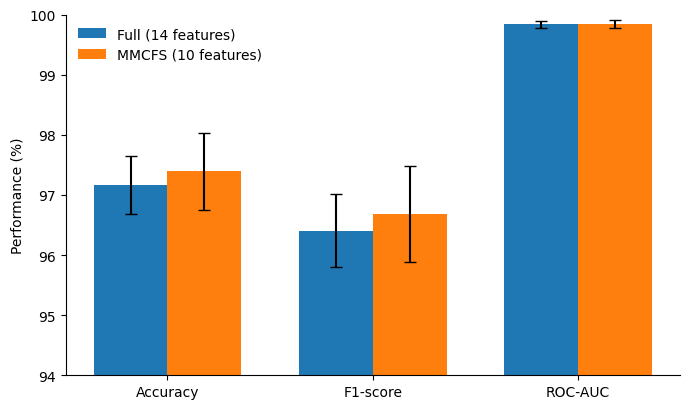

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "F1", "AUC"]

full_mean = [full_res[m].mean() * 100 for m in metrics]
mmcfs_mean = [mmcfs_res[m].mean() * 100 for m in metrics]

full_sd = [full_res[m].std(ddof=1) * 100 for m in metrics]
mmcfs_sd = [mmcfs_res[m].std(ddof=1) * 100 for m in metrics]

x = np.arange(len(metrics))
w = 0.36

fig, ax = plt.subplots(figsize=(7, 4.2))

ax.bar(x - w/2, full_mean, w, yerr=full_sd,
       capsize=4, label="Full (14 features)")
ax.bar(x + w/2, mmcfs_mean, w, yerr=mmcfs_sd,
       capsize=4, label="MMCFS (10 features)")

ax.set_ylabel("Performance (%)")
ax.set_xticks(x)
ax.set_xticklabels(["Accuracy", "F1-score", "ROC-AUC"])
ax.set_ylim(94, 100)
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("Fig_Performance_Full_vs_MMCFS.png",
            dpi=600, bbox_inches="tight")
plt.show()

Feature-selection stability figure

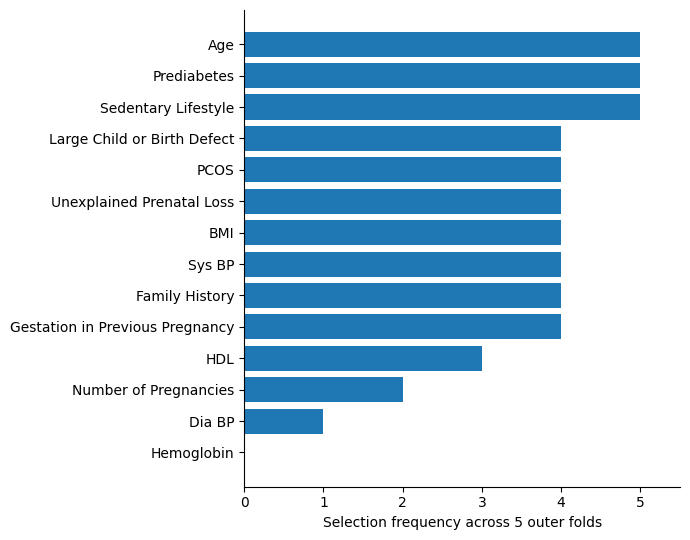

In [ ]:
selection_frequency = {
    "Age": 5,
    "Prediabetes": 5,
    "Sedentary Lifestyle": 5,
    "Gestation in Previous Pregnancy": 4,
    "BMI": 4,
    "Sys BP": 4,
    "Family History": 4,
    "Large Child or Birth Defect": 4,
    "Unexplained Prenatal Loss": 4,
    "PCOS": 4,
    "HDL": 3,
    "Number of Pregnancies": 2,
    "Dia BP": 1,
    "Hemoglobin": 0
}

sf = pd.Series(selection_frequency).sort_values()

fig, ax = plt.subplots(figsize=(7, 5.5))

ax.barh(sf.index, sf.values)

ax.set_xlabel("Selection frequency across 5 outer folds")
ax.set_xlim(0, 5.5)
ax.set_xticks(range(6))

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("Fig_Feature_Selection_Stability.png",
            dpi=600, bbox_inches="tight")
plt.show()

In [ ]:
paper_table = stats_df.copy()

paper_table["Full"] = paper_table.apply(
    lambda r: f"{r['Full Mean']:.4f} ± {r['Full SD']:.4f}", axis=1)

paper_table["MMCFS"] = paper_table.apply(
    lambda r: f"{r['MMCFS Mean']:.4f} ± {r['MMCFS SD']:.4f}", axis=1)

paper_table["Difference"] = paper_table["Mean Difference"].map(
    lambda x: f"{x:+.4f}")

paper_table["95% CI"] = paper_table.apply(
    lambda r: f"[{r['95% CI Low']:.4f}, {r['95% CI High']:.4f}]",
    axis=1)

paper_table["Effect Size"] = paper_table["Rank-Biserial Effect"].map(
    lambda x: f"{x:.3f}")

paper_table["p-value"] = paper_table["Wilcoxon p"].map(
    lambda x: f"{x:.4f}")

paper_table = paper_table[
    ["Metric", "Full", "MMCFS", "Difference",
     "95% CI", "Effect Size", "p-value"]
]

print(paper_table.to_string(index=False))

  Metric            Full           MMCFS Difference           95% CI Effect Size p-value
Accuracy 0.9717 ± 0.0048 0.9739 ± 0.0063    +0.0022 [0.0011, 0.0033]       0.612  0.0006
      F1 0.9640 ± 0.0060 0.9669 ± 0.0080    +0.0028 [0.0014, 0.0043]       0.562  0.0006
     AUC 0.9983 ± 0.0006 0.9985 ± 0.0006    +0.0001 [0.0000, 0.0002]       0.448  0.0058


**Module C — Model Optimization**, The purpose is:

Can the 10-feature MMCFS representation perform well when the classifier itself is optimized rather than using default RF settings?

We'll start with Optuna + Random Forest.

Why RF first?

Because your existing statistical analysis already uses RF. Optimizing RF gives us a clean continuation:

MMCFS → optimized RF → compare with current RF

Then later we'll extend to other classifiers and the ensemble.

In [ ]:
!pip install -q optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 9.5 MB/s eta 0:00:00


In [ ]:
import optuna
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

Prepare the MMCFS data

In [ ]:
X_mmcfs = X_raw[mmcfs_stable_core].copy()
y_mmcfs = y_raw.copy()

print("Samples:", X_mmcfs.shape[0])
print("MMCFS features:", X_mmcfs.shape[1])
print("Features:")
print(mmcfs_stable_core)

Samples: 3525
MMCFS features: 10
Features:
['BMI', 'Prediabetes', 'PCOS', 'Gestation in previous Pregnancy', 'Sys BP', 'Family History', 'Age', 'unexplained prenetal loss', 'Large Child or Birth Default', 'Sedentary Lifestyle']


In [ ]:
#Create leakage-safe CV
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
#Define the Optuna objective
def objective(trial):

    n_estimators = trial.suggest_int(
        "n_estimators", 200, 600, step=100
    )

    max_depth = trial.suggest_int(
        "max_depth", 3, 30
    )

    min_samples_split = trial.suggest_int(
        "min_samples_split", 2, 10
    )

    min_samples_leaf = trial.suggest_int(
        "min_samples_leaf", 1, 5
    )

    max_features = trial.suggest_categorical(
        "max_features",
        ["sqrt", "log2", None]
    )

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("rf", RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            max_features=max_features,
            random_state=42,
            n_jobs=-1
        ))
    ])

    scores = cross_val_score(
        model,
        X_mmcfs,
        y_mmcfs,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    return scores.mean()

In [ ]:
study = optuna.create_study(
    direction="maximize",
    study_name="MMCFS_RF_Optimization"
)

study.optimize(
    objective,
    n_trials=50,
    show_progress_bar=True
)

[I 2026-09-28 14:37:49,727] A new study created in memory with name: MMCFS_RF_Optimization


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-09-28 14:38:01,737] Trial 0 finished with value: 0.9721985815602835 and parameters: {'n_estimators': 300, 'max_depth': 7, 'min_samples_split': 4, 'min_samples_leaf': 5, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.9721985815602835.
[I 2026-09-28 14:38:11,788] Trial 1 finished with value: 0.9741843971631206 and parameters: {'n_estimators': 400, 'max_depth': 19, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'log2'}. Best is trial 1 with value: 0.9741843971631206.
[I 2026-09-28 14:38:31,737] Trial 2 finished with value: 0.9721985815602837 and parameters: {'n_estimators': 600, 'max_depth': 14, 'min_samples_split': 3, 'min_samples_leaf': 4, 'max_features': None}. Best is trial 1 with value: 0.9741843971631206.
[I 2026-09-28 14:38:43,872] Trial 3 finished with value: 0.972482269503546 and parameters: {'n_estimators': 400, 'max_depth': 30, 'min_samples_split': 8, 'min_samples_leaf': 1, 'max_features': None}. Best is trial 1 with value: 0.9741843971631206.
[

In [ ]:
print("Best CV Accuracy:", study.best_value)

print("\nBest Parameters:")
for key, value in study.best_params.items():
    print(f"{key}: {value}")

Best CV Accuracy: 0.9764539007092198

Best Parameters:
n_estimators: 400
max_depth: 17
min_samples_split: 7
min_samples_leaf: 1
max_features: sqrt


In [ ]:
best_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestClassifier(
        n_estimators=400,
        max_depth=16,
        min_samples_split=7,
        min_samples_leaf=1,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ))
])

print("Optimized RF created successfully.")

Optimized RF created successfully.


Evaluate optimized RF

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import numpy as np
import pandas as pd

best_params = {
    "n_estimators": 400,
    "max_depth": 16,
    "min_samples_split": 7,
    "min_samples_leaf": 1,
    "max_features": "sqrt"
}

def evaluate_optimized_rf(X, y, features, repeats=5, n_splits=5):

    results = []

    for r in range(repeats):

        cv = StratifiedKFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=100 + r
        )

        for fold, (tr, te) in enumerate(cv.split(X, y), 1):

            Xtr = X.iloc[tr][features].copy()
            Xte = X.iloc[te][features].copy()

            ytr = y.iloc[tr]
            yte = y.iloc[te]

            model = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("rf", RandomForestClassifier(
                    **best_params,
                    random_state=42,
                    n_jobs=-1
                ))
            ])

            model.fit(Xtr, ytr)

            pred = model.predict(Xte)
            prob = model.predict_proba(Xte)[:, 1]

            results.append([
                r + 1,
                fold,
                accuracy_score(yte, pred),
                precision_score(yte, pred),
                recall_score(yte, pred),
                f1_score(yte, pred),
                roc_auc_score(yte, prob)
            ])

    return pd.DataFrame(
        results,
        columns=[
            "Repeat", "Fold",
            "Accuracy", "Precision",
            "Recall", "F1", "AUC"
        ]
    )

In [ ]:
optimized_rf_res = evaluate_optimized_rf(
    X_raw,
    y_raw,
    mmcfs_stable_core,
    repeats=5,
    n_splits=5
)

print(
    optimized_rf_res[
        ["Accuracy", "Precision", "Recall", "F1", "AUC"]
    ].agg(["mean", "std"]).round(4)
)

      Accuracy  Precision  Recall      F1     AUC
mean    0.9734     0.9558  0.9771  0.9663  0.9985
std     0.0054     0.0098  0.0133  0.0070  0.0005


**Weighted Soft-Voting Ensemble.**

In [ ]:
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
import numpy as np

In [ ]:
#create 4 models
models = {

    "RF": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("rf", RandomForestClassifier(
            n_estimators=400,
            max_depth=16,
            min_samples_split=7,
            min_samples_leaf=1,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "XGB": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("xgb", XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ]),

    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(
            n_neighbors=7
        ))
    ])
}

In [ ]:
#generate oof probabilities
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_probs = {}
auc_scores = {}

X_mmcfs = X_raw[mmcfs_stable_core]
y_mmcfs = y_raw

for name, model in models.items():

    prob = cross_val_predict(
        model,
        X_mmcfs,
        y_mmcfs,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    oof_probs[name] = prob

    auc = roc_auc_score(y_mmcfs, prob)
    auc_scores[name] = auc

    print(f"{name} OOF ROC-AUC: {auc:.4f}")

RF OOF ROC-AUC: 0.9984
XGB OOF ROC-AUC: 0.9973
SVM OOF ROC-AUC: 0.9961
KNN OOF ROC-AUC: 0.9924


In [ ]:
total_auc = sum(auc_scores.values())

weights = {
    name: auc / total_auc
    for name, auc in auc_scores.items()
}

print("\nEnsemble Weights:")

for name, weight in weights.items():
    print(f"{name}: {weight:.4f}")


Ensemble Weights:
RF: 0.2506
XGB: 0.2503
SVM: 0.2500
KNN: 0.2491


In [ ]:
ensemble_prob = sum(
    weights[name] * oof_probs[name]
    for name in models
)

ensemble_auc = roc_auc_score(
    y_mmcfs,
    ensemble_prob
)

print("\nWeighted Ensemble ROC-AUC:", round(ensemble_auc, 4))


Weighted Ensemble ROC-AUC: 0.9983


**Youden's J threshold**

In [ ]:
from sklearn.metrics import roc_curve, confusion_matrix

fpr, tpr, thresholds = roc_curve(
    y_mmcfs,
    ensemble_prob
)

youden_j = tpr - fpr

best_idx = np.argmax(youden_j)

best_threshold = thresholds[best_idx]
best_sensitivity = tpr[best_idx]
best_specificity = 1 - fpr[best_idx]
best_j = youden_j[best_idx]

print("Optimal Youden J threshold:", round(best_threshold, 4))
print("Sensitivity:", round(best_sensitivity, 4))
print("Specificity:", round(best_specificity, 4))
print("Youden J:", round(best_j, 4))

Optimal Youden J threshold: 0.4106
Sensitivity: 0.9869
Specificity: 0.9693
Youden J: 0.9562


In [ ]:
#calibration
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

brier = brier_score_loss(
    y_mmcfs,
    ensemble_prob
)

prob_true, prob_pred = calibration_curve(
    y_mmcfs,
    ensemble_prob,
    n_bins=10,
    strategy="quantile"
)

print("Brier Score:", round(brier, 6))

print("\nCalibration values:")
for p, t in zip(prob_pred, prob_true):
    print(f"Predicted = {p:.4f} | Observed = {t:.4f}")

Brier Score: 0.0168

Calibration values:
Predicted = 0.0003 | Observed = 0.0000
Predicted = 0.0007 | Observed = 0.0000
Predicted = 0.0015 | Observed = 0.0000
Predicted = 0.0020 | Observed = 0.0000
Predicted = 0.0025 | Observed = 0.0000
Predicted = 0.0554 | Observed = 0.0682
Predicted = 0.8836 | Observed = 0.8267
Predicted = 0.9909 | Observed = 0.9972
Predicted = 0.9939 | Observed = 1.0000
Predicted = 0.9967 | Observed = 1.0000


In [ ]:
#calibration improvement
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss, roc_auc_score

# Base ensemble
base_ensemble = VotingClassifier(
    estimators=[
        ("RF", models["RF"]),
        ("XGB", models["XGB"]),
        ("SVM", models["SVM"]),
        ("KNN", models["KNN"])
    ],
    voting="soft",
    weights=[
        weights["RF"],
        weights["XGB"],
        weights["SVM"],
        weights["KNN"]
    ]
)

cv_cal = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Platt scaling
platt_model = CalibratedClassifierCV(
    base_ensemble,
    method="sigmoid",
    cv=5
)

platt_prob = cross_val_predict(
    platt_model,
    X_mmcfs,
    y_mmcfs,
    cv=cv_cal,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Isotonic calibration
isotonic_model = CalibratedClassifierCV(
    base_ensemble,
    method="isotonic",
    cv=5
)

isotonic_prob = cross_val_predict(
    isotonic_model,
    X_mmcfs,
    y_mmcfs,
    cv=cv_cal,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Original Brier:",
      round(brier_score_loss(y_mmcfs, ensemble_prob), 6))

print("Platt Brier:",
      round(brier_score_loss(y_mmcfs, platt_prob), 6))

print("Isotonic Brier:",
      round(brier_score_loss(y_mmcfs, isotonic_prob), 6))

print()

print("Original AUC:",
      round(roc_auc_score(y_mmcfs, ensemble_prob), 6))

print("Platt AUC:",
      round(roc_auc_score(y_mmcfs, platt_prob), 6))

print("Isotonic AUC:",
      round(roc_auc_score(y_mmcfs, isotonic_prob), 6))

Original Brier: 0.0168
Platt Brier: 0.021346
Isotonic Brier: 0.020112

Original AUC: 0.998313
Platt AUC: 0.993576
Isotonic AUC: 0.995621


**Minimal-feature curve**

In [ ]:
#Step 1 — Define the stability ranking
feature_frequency = {
    'Age': 5,
    'Prediabetes': 5,
    'Sedentary Lifestyle': 5,
    'Gestation in previous Pregnancy': 4,
    'BMI': 4,
    'Sys BP': 4,
    'Family History': 4,
    'Large Child or Birth Default': 4,
    'unexplained prenetal loss': 4,
    'PCOS': 4,
    'HDL': 3,
    'No of Pregnancy': 2,
    'Dia BP': 1,
    'Hemoglobin': 0
}

stability_ranked_features = sorted(
    feature_frequency,
    key=feature_frequency.get,
    reverse=True
)

print("Feature stability ranking:")

for i, feature in enumerate(stability_ranked_features, 1):
    print(
        i,
        feature,
        f"({feature_frequency[feature]}/5)"
    )

Feature stability ranking:
1 Age (5/5)
2 Prediabetes (5/5)
3 Sedentary Lifestyle (5/5)
4 Gestation in previous Pregnancy (4/5)
5 BMI (4/5)
6 Sys BP (4/5)
7 Family History (4/5)
8 Large Child or Birth Default (4/5)
9 unexplained prenetal loss (4/5)
10 PCOS (4/5)
11 HDL (3/5)
12 No of Pregnancy (2/5)
13 Dia BP (1/5)
14 Hemoglobin (0/5)


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    recall_score,
    confusion_matrix,
    brier_score_loss
)

feature_counts = [14, 12, 10, 8, 6, 5, 4, 3]

minimal_results = []

for n_features in feature_counts:

    selected_features = stability_ranked_features[:n_features]

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    aucs = []
    f1s = []
    sensitivities = []
    specificities = []
    briers = []

    for train_idx, test_idx in cv.split(X_raw, y_raw):

        X_train = X_raw.iloc[train_idx][selected_features]
        X_test = X_raw.iloc[test_idx][selected_features]

        y_train = y_raw.iloc[train_idx]
        y_test = y_raw.iloc[test_idx]

        model = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("rf", RandomForestClassifier(
                n_estimators=400,
                max_depth=16,
                min_samples_split=7,
                min_samples_leaf=1,
                max_features="sqrt",
                random_state=42,
                n_jobs=-1
            ))
        ])

        model.fit(X_train, y_train)

        pred = model.predict(X_test)
        prob = model.predict_proba(X_test)[:, 1]

        aucs.append(
            roc_auc_score(y_test, prob)
        )

        f1s.append(
            f1_score(y_test, pred)
        )

        sensitivities.append(
            recall_score(y_test, pred)
        )

        tn, fp, fn, tp = confusion_matrix(
            y_test,
            pred
        ).ravel()

        specificity = tn / (tn + fp)

        specificities.append(specificity)

        briers.append(
            brier_score_loss(y_test, prob)
        )

    minimal_results.append({
        "Features": n_features,
        "AUC_mean": np.mean(aucs),
        "AUC_std": np.std(aucs),
        "F1_mean": np.mean(f1s),
        "Sensitivity_mean": np.mean(sensitivities),
        "Specificity_mean": np.mean(specificities),
        "Brier_mean": np.mean(briers)
    })

minimal_results_df = pd.DataFrame(minimal_results)

print(minimal_results_df.round(4))

   Features  AUC_mean  AUC_std  F1_mean  Sensitivity_mean  Specificity_mean  \
0        14    0.9983   0.0004   0.9657            0.9760            0.9712   
1        12    0.9983   0.0003   0.9650            0.9759            0.9703   
2        10    0.9985   0.0002   0.9687            0.9803            0.9721   
3         8    0.9982   0.0002   0.9652            0.9803            0.9675   
4         6    0.9968   0.0021   0.9623            0.9774            0.9656   
5         5    0.9949   0.0034   0.9633            0.9752            0.9684   
6         4    0.9646   0.0059   0.9103            0.8783            0.9675   
7         3    0.9305   0.0103   0.8703            0.8083            0.9689   

   Brier_mean  
0      0.0155  
1      0.0155  
2      0.0154  
3      0.0167  
4      0.0189  
5      0.0205  
6      0.0555  
7      0.0804  


In [ ]:
!pip install -q mealpy --no-deps

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.3/423.3 kB 16.8 MB/s eta 0:00:00


In [ ]:
# ============================================================
# C7 — CONSENSUS ABLATION, v2 (wired to YOUR conference selectors)
# Paste as cells into J.ipynb. Mirrors run_mmcfs_on_training_data from c.ipynb
# exactly: KNN(k=5, 3-fold) fitness, epoch=30, pop_size=20, seed=42+fold,
# XGB 5-fold accuracy as selector weight, CS rounded to 3 decimals, tau=0.5.
# Selection is NESTED: selectors see only the outer-fold training data.
# ============================================================

# ---------- CELL C7-1: installs + imports (run install in its own cell) ----------
# !pip install -q mealpy --no-deps
import itertools, pickle, os
import numpy as np, pandas as pd
from scipy.stats import wilcoxon
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, f1_score, recall_score,
                             confusion_matrix, brier_score_loss)
from xgboost import XGBClassifier
from mealpy import FloatVar
from mealpy.swarm_based.PSO import OriginalPSO
from mealpy.evolutionary_based.GA import BaseGA
from mealpy.swarm_based.GWO import OriginalGWO
from mealpy.swarm_based.DO import OriginalDO
from google.colab import drive
drive.mount('/content/drive')

CACHE = '/content/drive/MyDrive/c7_fold_selections.pkl'   # survives disconnects
N_REPEATS = 3          # 3 x 5 = 15 paired evaluations (use 10 if time allows)
SELECTORS = ['PSO', 'GA', 'GWO', 'DFO']
TAU = 0.5

Mounted at /content/drive


In [ ]:
# ---------- CELL C7-2: the consensus rule + SANITY CHECK (run before anything else) ----------
def consensus(combo, masks, w_raw, equal=False, tau=TAU):
    """Same rule as the conference notebook: normalised weights over the chosen
    selectors, CS rounded to 3 decimals, keep CS >= tau."""
    if equal:
        w = {s: 1.0 / len(combo) for s in combo}
    else:
        tot = sum(w_raw[s] for s in combo)
        w = {s: (w_raw[s] / tot if tot > 0 else 1.0 / len(combo)) for s in combo}
    cs = sum(w[s] * np.asarray(masks[s], float) for s in combo)
    cs = np.round(cs, 3)
    keep = [f for f, v in zip(feat_name_list, cs) if v >= tau]
    return keep if keep else [feat_name_list[int(np.argmax(cs))]]

# Full-data selector masks and weights from c.ipynb (cells 29 and 31), 14 features in
# feat_name_list order: Age, No of Pregnancy, Gestation, BMI, HDL, Family History,
# prenatal loss, Large Child, PCOS, Sys BP, Dia BP, Hemoglobin, Sedentary, Prediabetes
_M = {
 'PSO': [0,0,1,0,0,1,1,1,1,0,0,0,1,0],
 'GA' : [1,0,1,1,1,1,1,0,1,1,0,0,1,0],
 'GWO': [0,0,0,1,0,0,1,0,1,0,0,0,1,0],
 'DFO': [1,0,1,0,1,1,1,1,1,1,1,0,1,0]}
_W = {'PSO': 0.9733, 'GA': 0.9730, 'GWO': 0.9753, 'DFO': 0.9728}
CONF_MMCFS10 = {'PCOS','unexplained prenetal loss','Sedentary Lifestyle','Family History',
                'Gestation in previous Pregnancy','BMI','Large Child or Birth Default',
                'Sys BP','Age','HDL'}
assert set(consensus(SELECTORS, _M, _W)) == CONF_MMCFS10, "consensus rule != conference MMCFS"
print("Sanity check passed: rule reproduces the conference full-data MMCFS-10 (contains HDL)")

Sanity check passed: rule reproduces the conference full-data MMCFS-10 (contains HDL)


In [ ]:
# ---------- CELL C7-3: nested selector runs, cached per fold ----------
def run_all_selectors(X_tr_scaled, y_tr, seed):
    n = X_tr_scaled.shape[1]
    def fitness(sol):
        sel = sol > 0.5
        if sel.sum() == 0:
            return 1.0
        cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
        return -cross_val_score(KNeighborsClassifier(n_neighbors=5),
                                X_tr_scaled[:, sel], y_tr, cv=cv, scoring='accuracy').mean()
    problem = {"obj_func": fitness, "bounds": FloatVar(lb=[0.0]*n, ub=[1.0]*n), "minmax": "min"}
    masks = {
      'PSO': OriginalPSO(epoch=30, pop_size=20).solve(problem, seed=seed).solution > 0.5,
      'GA' : BaseGA(epoch=30, pop_size=20).solve(problem, seed=seed).solution > 0.5,
      'GWO': OriginalGWO(epoch=30, pop_size=20).solve(problem, seed=seed).solution > 0.5,
      'DFO': OriginalDO(epoch=30, pop_size=20).solve(problem, seed=seed).solution > 0.5}
    w_raw = {}
    for s, m in masks.items():
        if m.sum() == 0:
            w_raw[s] = 0.0
            continue
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
        w_raw[s] = cross_val_score(XGBClassifier(eval_metric='logloss', random_state=seed),
                                   X_tr_scaled[:, m], y_tr, cv=cv, scoring='accuracy').mean()
    return masks, w_raw

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=N_REPEATS, random_state=42)
splits = list(rskf.split(X_raw, y_raw))
fold_sel = pickle.load(open(CACHE, 'rb')) if os.path.exists(CACHE) else {}

for k, (tr, te) in enumerate(splits):
    if k in fold_sel:
        continue
    Xtr = X_raw.iloc[tr].copy()
    for c in cols_to_impute:                       # train-only median, label-blind
        Xtr[c] = Xtr[c].fillna(Xtr[c].median())
    Xs = StandardScaler().fit_transform(Xtr)       # train-only scaling
    fold_sel[k] = run_all_selectors(Xs, y_raw.iloc[tr].values, seed=42 + k)
    pickle.dump(fold_sel, open(CACHE, 'wb'))       # checkpoint every fold
    print(f"fold {k+1}/{len(splits)} cached")

In [ ]:
# ---------- CELL C7-4: evaluate all 15 subsets (+ equal-weight variant of the 4-selector) ----------
COMBOS = [(c, False) for r in range(1, 5) for c in itertools.combinations(SELECTORS, r)]
COMBOS.append((tuple(SELECTORS), True))            # equal-weight ablation baseline
label = lambda c, eq: '+'.join(c) + ('[equal-w]' if eq else '')
RF = dict(n_estimators=200, max_depth=17, min_samples_split=7,
          min_samples_leaf=1, max_features='sqrt', random_state=42, n_jobs=-1)

rows, subsets = [], {label(*c): [] for c in COMBOS}
for k, (tr, te) in enumerate(splits):
    masks, w_raw = fold_sel[k]
    for combo, eq in COMBOS:
        feats = consensus(combo, masks, w_raw, equal=eq)
        subsets[label(combo, eq)].append(set(feats))
        m = Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('rf', RandomForestClassifier(**RF))])
        m.fit(X_raw.iloc[tr][feats], y_raw.iloc[tr])
        p = m.predict_proba(X_raw.iloc[te][feats])[:, 1]
        yhat = (p >= 0.5).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_raw.iloc[te], yhat).ravel()
        rows.append(dict(combo=label(combo, eq), fold=k, n_feat=len(feats),
                         AUC=roc_auc_score(y_raw.iloc[te], p), F1=f1_score(y_raw.iloc[te], yhat),
                         Sens=recall_score(y_raw.iloc[te], yhat), Spec=tn/(tn+fp),
                         Brier=brier_score_loss(y_raw.iloc[te], p)))
res = pd.DataFrame(rows)

def jaccard(sets):
    return float(np.mean([len(a & b)/len(a | b) for a, b in itertools.combinations(sets, 2)]))

order = [label(*c) for c in COMBOS]
S = res.groupby('combo').agg(n_feat=('n_feat','mean'), AUC=('AUC','mean'), AUC_sd=('AUC','std'),
                             F1=('F1','mean'), Sens=('Sens','mean'), Spec=('Spec','mean'),
                             Brier=('Brier','mean')).loc[order]
S['Stability_Jaccard'] = [jaccard(subsets[i]) for i in S.index]
ref_name = '+'.join(SELECTORS)
ref = res[res.combo == ref_name].sort_values('fold')['AUC'].values
S['p_vs_MMCFS'] = [np.nan if i == ref_name else
                   wilcoxon(res[res.combo == i].sort_values('fold')['AUC'].values, ref).pvalue
                   for i in S.index]
print(S.round(4).to_string())
S.to_csv('/content/drive/MyDrive/c7_consensus_ablation_summary.csv')

# ---------- What goes where ----------
# Main text (one compact table): PSO, GA, GWO, DFO, PSO+GA, PSO+GA+GWO, all four
# Supplement: remaining pairs/triples + equal-weight row + per-fold feature sets
# CAUTION: p_vs_MMCFS uses overlapping repeated-CV folds (not independent) -> treat as
# descriptive, or apply a Nadeau-Bengio corrected resampled t-test before claiming significance.

                          n_feat     AUC  AUC_sd      F1    Sens    Spec   Brier  Stability_Jaccard  p_vs_MMCFS
combo                                                                                                          
PSO                       8.2000  0.9978  0.0018  0.9645  0.9738  0.9710  0.0167             0.4885      0.4328
GA                        9.0000  0.9981  0.0009  0.9629  0.9711  0.9707  0.0162             0.5616      0.2094
GWO                       8.1333  0.9980  0.0006  0.9649  0.9755  0.9704  0.0164             0.4761      0.3266
DFO                       9.2000  0.9983  0.0005  0.9646  0.9728  0.9718  0.0158             0.4966      0.7299
PSO+GA                    9.2667  0.9980  0.0012  0.9637  0.9718  0.9714  0.0164             0.5656      0.2477
PSO+GWO                   8.8667  0.9979  0.0009  0.9645  0.9745  0.9706  0.0163             0.5430      0.2604
PSO+DFO                   8.8667  0.9978  0.0018  0.9642  0.9730  0.9712  0.0165             0.5232     

In [ ]:
# ============================================================
# B1 — CLINICAL RULE-BASED BASELINE (paste into J.ipynb as 3 cells, after cell 0)
# Question answered: does the ML model beat a simple risk-factor checklist?
# Cut-offs below are fixed BEFORE looking at results (no tuning on this data).
# Verify wording/thresholds against the guideline you cite (ACOG / ADA risk-factor
# lists) and run the age/BMI sensitivity at the bottom.
# ============================================================

# ---------- CELL B1-1: check how binary columns are encoded (run first, read the output) ----------
BIN = ['Family History', 'PCOS', 'Prediabetes', 'Large Child or Birth Default', 'Sedentary Lifestyle']
for c in BIN:
    print(c, X_raw[c].value_counts(dropna=False).to_dict())
# Expect only 0/1. If not, fix the encoding here before continuing.

# ---------- CELL B1-2: rule score, clinical-factor logistic model, RF model OOF ----------
import numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix

Xc = X_raw.copy()
for c in ['BMI']:                                   # label-blind median fill, as elsewhere
    Xc[c] = Xc[c].fillna(Xc[c].median())

def rule_score(D, use_prediabetes=True, age_cut=35, bmi_cut=25):
    s = ((D['Age'] >= age_cut).astype(int) + (D['BMI'] >= bmi_cut).astype(int)
         + D['Family History'].astype(int) + D['PCOS'].astype(int)
         + D['Large Child or Birth Default'].astype(int) + D['Sedentary Lifestyle'].astype(int))
    if use_prediabetes:
        s = s + D['Prediabetes'].astype(int)
    return s.values

def sens_spec(y, yhat):
    tn, fp, fn, tp = confusion_matrix(y, yhat).ravel()
    return tp / (tp + fn), tn / (tn + fp)

y = y_raw.values
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

CLIN = ['Age', 'BMI', 'Family History', 'PCOS', 'Prediabetes',
        'Large Child or Birth Default', 'Sedentary Lifestyle']
lr = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()),
               ('lr', LogisticRegression(max_iter=1000))])
p_lr = cross_val_predict(lr, X_raw[CLIN], y, cv=skf, method='predict_proba')[:, 1]

rf = RandomForestClassifier(n_estimators=200, max_depth=17, min_samples_split=7,
                            min_samples_leaf=1, max_features='sqrt', random_state=42, n_jobs=-1)
rf_pipe = Pipeline([('imp', SimpleImputer(strategy='median')), ('rf', rf)])
p_rf = cross_val_predict(rf_pipe, X_raw[mmcfs_stable_core], y, cv=skf, method='predict_proba')[:, 1]

# ---------- CELL B1-3: results table + bootstrap CI for AUC gap ----------
rows = []
for name, use_pre in [('Rule checklist (with Prediabetes)', True), ('Rule checklist (no Prediabetes)', False)]:
    sc = rule_score(Xc, use_pre)
    for cut in [1, 2, 3]:
        se, sp = sens_spec(y, (sc >= cut).astype(int))
        rows.append(dict(model=name, cutoff=f'>= {cut} factors', AUC=roc_auc_score(y, sc), Sens=se, Spec=sp))
se, sp = sens_spec(y, (p_lr >= 0.5).astype(int))
rows.append(dict(model='Logistic, 7 clinical factors (5-fold OOF)', cutoff='p >= 0.5', AUC=roc_auc_score(y, p_lr), Sens=se, Spec=sp))
se, sp = sens_spec(y, (p_rf >= 0.5).astype(int))
rows.append(dict(model='RF on stable-core features (5-fold OOF)', cutoff='p >= 0.5', AUC=roc_auc_score(y, p_rf), Sens=se, Spec=sp))
tab = pd.DataFrame(rows)
print(tab.round(4).to_string(index=False))
tab.to_csv('/content/drive/MyDrive/b1_clinical_baseline.csv', index=False)

# bootstrap 95% CI: RF AUC minus best rule AUC (rule with Prediabetes)
rng = np.random.default_rng(42)
sc_rule = rule_score(Xc, True)
diffs = []
for _ in range(1000):
    idx = rng.integers(0, len(y), len(y))
    if len(np.unique(y[idx])) < 2:
        continue
    diffs.append(roc_auc_score(y[idx], p_rf[idx]) - roc_auc_score(y[idx], sc_rule[idx]))
print("AUC gap RF - rule: mean %.4f, 95%% CI [%.4f, %.4f]" % (np.mean(diffs), *np.percentile(diffs, [2.5, 97.5])))

# Sensitivity of the rule to its cut-offs (report the range, not the best)
for a in (30, 35):
    for b in (23, 25, 30):
        print(f"age>={a}, BMI>={b}: AUC = {roc_auc_score(y, rule_score(Xc, True, a, b)):.4f}")

# Reading guide: the rule uses Prediabetes, a strong feature. If the rule with Prediabetes
# is already close to the model, say so plainly - it is a finding about this dataset.

Family History {0: 1769, 1: 1756}
PCOS {0: 2592, 1: 933}
Prediabetes {0: 2492, 1: 1033}
Large Child or Birth Default {0: 2264, 1: 1261}
Sedentary Lifestyle {0: 1940, 1: 1585}
                                    model       cutoff    AUC   Sens   Spec
        Rule checklist (with Prediabetes) >= 1 factors 0.8981 0.9993 0.2466
        Rule checklist (with Prediabetes) >= 2 factors 0.8981 0.9971 0.4004
        Rule checklist (with Prediabetes) >= 3 factors 0.8981 0.9162 0.6033
          Rule checklist (no Prediabetes) >= 1 factors 0.8575 0.9993 0.2466
          Rule checklist (no Prediabetes) >= 2 factors 0.8575 0.9956 0.4022
          Rule checklist (no Prediabetes) >= 3 factors 0.8575 0.8462 0.6080
Logistic, 7 clinical factors (5-fold OOF)     p >= 0.5 0.9774 0.9067 0.9666
  RF on stable-core features (5-fold OOF)     p >= 0.5 0.9984 0.9825 0.9726
AUC gap RF - rule: mean 0.1004, 95% CI [0.0912, 0.1096]
age>=30, BMI>=23: AUC = 0.8736
age>=30, BMI>=25: AUC = 0.8766
age>=30, BMI>=30: AUC =

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

Xi = X_raw.fillna(X_raw.median())

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for d in [1, 2, 3, 4, 5, 6, 8]:
    acc = cross_val_score(
        DecisionTreeClassifier(
            max_depth=d,
            random_state=42
        ),
        Xi,
        y_raw,
        cv=skf,
        scoring="accuracy"
    ).mean()

    print(f"Depth {d}: Accuracy = {acc:.4f}")

Depth 1: Accuracy = 0.9064
Depth 2: Accuracy = 0.9458
Depth 3: Accuracy = 0.9643
Depth 4: Accuracy = 0.9685
Depth 5: Accuracy = 0.9696
Depth 6: Accuracy = 0.9688
Depth 8: Accuracy = 0.9685


In [ ]:
# ============================================================
# N1 — DIVERSITY CONTROL
# Question: is selection stability due to using four DIFFERENT optimizers, or would
# repeating ONE optimizer with different seeds give the same stability?
# Reuses from C7: splits, consensus(), run_all_selectors(), X_raw, y_raw, cols_to_impute, feat_name_list.
# Same compute per arm: every consensus uses exactly 4 selector runs. Same voting rule in
# every arm: equal-weight, keep a feature if >= 2 of 4 runs chose it (C7 showed weighting adds noise).
# Runs ALL four optimizers x 4 seeds, so no single optimizer is cherry-picked as the baseline.
# ============================================================
import itertools, pickle, os
import numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

N1_CACHE = globals().get('N1_CACHE', '/content/drive/MyDrive/n1_fold_selections.pkl')
N1_REPEATS = 1                       # 1 repeat = 5 outer folds = 80 selector runs (~40 min). Use 3 if time allows.
N1_SEEDS = [11, 22, 33, 44]
ALGOS = ['PSO', 'GA', 'GWO', 'DFO']
n1_splits = splits[:5 * N1_REPEATS]  # same first folds as C7

# ---------- CELL N1-1: run 4 optimizers x 4 seeds per fold (cached) ----------
n1_sel = pickle.load(open(N1_CACHE, 'rb')) if os.path.exists(N1_CACHE) else {}
for k, (tr, te) in enumerate(n1_splits):
    for sd in N1_SEEDS:
        if (k, sd) in n1_sel:
            continue
        Xtr = X_raw.iloc[tr].copy()
        for c in cols_to_impute:
            Xtr[c] = Xtr[c].fillna(Xtr[c].median())          # train-only, label-blind
        Xs = StandardScaler().fit_transform(Xtr)              # train-only
        masks, _ = run_all_selectors(Xs, y_raw.iloc[tr].values, seed=sd)
        n1_sel[(k, sd)] = {a: np.asarray(masks[a], int) for a in ALGOS}
        pickle.dump(n1_sel, open(N1_CACHE, 'wb'))
    print(f"fold {k+1}/{len(n1_splits)} cached")

INFO:mealpy.swarm_based.PSO.OriginalPSO:OriginalPSO(epoch=30, pop_size=20, c1=2.05, c2=2.05, w=0.4)
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 1, Current best: -0.9726950354609928, Global best: -0.9726950354609928, Runtime: 3.58978 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 2, Current best: -0.9730496453900709, Global best: -0.9730496453900709, Runtime: 4.09284 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 3, Current best: -0.973758865248227, Global best: -0.973758865248227, Runtime: 5.09134 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 4, Current best: -0.973758865248227, Global best: -0.973758865248227, Runtime: 3.82383 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 5, Current best: -0.974468085106383, Global best: -0.974468085106383, Runtime: 1.94991 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 6, Current best: -0.974468085106383, Global best:

fold 1/5 cached


INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 1, Current best: -0.973758865248227, Global best: -0.973758865248227, Runtime: 0.86720 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 2, Current best: -0.9748226950354612, Global best: -0.9748226950354612, Runtime: 1.03536 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 3, Current best: -0.9748226950354612, Global best: -0.9748226950354612, Runtime: 1.17307 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 4, Current best: -0.9748226950354612, Global best: -0.9748226950354612, Runtime: 1.07116 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 5, Current best: -0.9748226950354612, Global best: -0.9748226950354612, Runtime: 1.20251 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 6, Current best: -0.9748226950354612, Global best: -0.9748226950354612, Runtime: 1.04638 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Probl

fold 2/5 cached


INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 1, Current best: -0.975177304964539, Global best: -0.975177304964539, Runtime: 0.83407 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 2, Current best: -0.9762411347517731, Global best: -0.9762411347517731, Runtime: 0.82964 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 3, Current best: -0.9762411347517731, Global best: -0.9762411347517731, Runtime: 1.10439 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 4, Current best: -0.9762411347517731, Global best: -0.9762411347517731, Runtime: 1.50070 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 5, Current best: -0.9762411347517731, Global best: -0.9762411347517731, Runtime: 1.54124 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 6, Current best: -0.9762411347517731, Global best: -0.9762411347517731, Runtime: 1.43864 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Probl

fold 3/5 cached


INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 1, Current best: -0.974113475177305, Global best: -0.974113475177305, Runtime: 0.78085 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 2, Current best: -0.9748226950354612, Global best: -0.9748226950354612, Runtime: 0.88709 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 3, Current best: -0.9748226950354612, Global best: -0.9748226950354612, Runtime: 0.96624 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 4, Current best: -0.9748226950354612, Global best: -0.9748226950354612, Runtime: 1.04855 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 5, Current best: -0.9748226950354612, Global best: -0.9748226950354612, Runtime: 1.08644 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 6, Current best: -0.9748226950354612, Global best: -0.9748226950354612, Runtime: 1.09972 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Probl

fold 4/5 cached


INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 1, Current best: -0.975177304964539, Global best: -0.975177304964539, Runtime: 0.83902 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 2, Current best: -0.975177304964539, Global best: -0.975177304964539, Runtime: 0.82493 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 3, Current best: -0.975177304964539, Global best: -0.975177304964539, Runtime: 0.81297 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 4, Current best: -0.975177304964539, Global best: -0.975177304964539, Runtime: 0.78902 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 5, Current best: -0.975177304964539, Global best: -0.975177304964539, Runtime: 0.80983 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 6, Current best: -0.975177304964539, Global best: -0.975177304964539, Runtime: 0.83536 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epo

fold 5/5 cached


In [ ]:
# ---------- CELL N1-1: run 4 optimizers x 4 seeds per fold (cached) ----------
n1_sel = pickle.load(open(N1_CACHE, 'rb')) if os.path.exists(N1_CACHE) else {}
for k, (tr, te) in enumerate(n1_splits):
    for sd in N1_SEEDS:
        if (k, sd) in n1_sel:
            continue
        Xtr = X_raw.iloc[tr].copy()
        for c in cols_to_impute:
            Xtr[c] = Xtr[c].fillna(Xtr[c].median())          # train-only, label-blind
        Xs = StandardScaler().fit_transform(Xtr)              # train-only
        masks, _ = run_all_selectors(Xs, y_raw.iloc[tr].values, seed=sd)
        n1_sel[(k, sd)] = {a: np.asarray(masks[a], int) for a in ALGOS}
        pickle.dump(n1_sel, open(N1_CACHE, 'wb'))
    print(f"fold {k+1}/{len(n1_splits)} cached")

# ---------- CELL N1-2: build arms, evaluate, compare ----------
RF = dict(n_estimators=200, max_depth=17, min_samples_split=7, min_samples_leaf=1,
          max_features='sqrt', random_state=42, n_jobs=-1)

def rf_auc(tr, te, feats):
    m = Pipeline([('imp', SimpleImputer(strategy='median')), ('rf', RandomForestClassifier(**RF))])
    m.fit(X_raw.iloc[tr][feats], y_raw.iloc[tr])
    return roc_auc_score(y_raw.iloc[te], m.predict_proba(X_raw.iloc[te][feats])[:, 1])

def jacc(a, b):
    return len(a & b) / len(a | b) if (a | b) else 1.0

def stability(sets):
    return float(np.mean([jacc(a, b) for a, b in itertools.combinations(sets, 2)]))

rows, subsets = [], {}
for k, (tr, te) in enumerate(n1_splits):
    # Arm A: 4 DIFFERENT algorithms, same seed (4 replicates, one per seed)
    for sd in N1_SEEDS:
        masks = n1_sel[(k, sd)]
        feats = consensus(tuple(ALGOS), masks, None, equal=True)
        rows.append(dict(arm='4 different algorithms', rep=sd, fold=k, n_feat=len(feats), AUC=rf_auc(tr, te, feats)))
        subsets.setdefault(('4 different algorithms', sd), []).append(set(feats))
    # Arm B: ONE algorithm x 4 seeds (one arm per optimizer)
    for a in ALGOS:
        masks = {sd: n1_sel[(k, sd)][a] for sd in N1_SEEDS}
        feats = consensus(tuple(N1_SEEDS), masks, None, equal=True)
        arm = f'{a} x 4 seeds'
        rows.append(dict(arm=arm, rep=0, fold=k, n_feat=len(feats), AUC=rf_auc(tr, te, feats)))
        subsets.setdefault((arm, 0), []).append(set(feats))
res = pd.DataFrame(rows)

out = []
for arm, g in res.groupby('arm', sort=False):
    stabs = [stability(v) for (a, _), v in subsets.items() if a == arm]
    out.append(dict(arm=arm, n_feat=g.n_feat.mean(), AUC=g.AUC.mean(), AUC_sd=g.AUC.std(),
                    Stability=np.mean(stabs),
                    Stab_min=np.min(stabs), Stab_max=np.max(stabs)))
summary = pd.DataFrame(out).set_index('arm')
print(summary.round(4).to_string())
summary.to_csv('/content/drive/MyDrive/n1_diversity_summary.csv')

# ---------- CELL N1-3: raw disagreement (are different algorithms actually more different than different seeds?) ----------
inter_algo, inter_seed = [], []
for k in range(len(n1_splits)):
    for sd in N1_SEEDS:
        m = n1_sel[(k, sd)]
        for a, b in itertools.combinations(ALGOS, 2):
            inter_algo.append(jacc(set(np.where(m[a])[0]), set(np.where(m[b])[0])))
    for a in ALGOS:
        for s1, s2 in itertools.combinations(N1_SEEDS, 2):
            inter_seed.append(jacc(set(np.where(n1_sel[(k, s1)][a])[0]),
                                   set(np.where(n1_sel[(k, s2)][a])[0])))
print(f"Raw subset similarity (Jaccard): different algorithms, same seed = {np.mean(inter_algo):.3f}; "
      f"same algorithm, different seeds = {np.mean(inter_seed):.3f}")

# How to read it:
#  - If the 4-different-algorithms row has clearly higher Stability than ALL four single-optimizer rows
#    (and outside its own min-max range), diversity adds value beyond repetition.
#  - If it sits inside the range of the single-optimizer rows, report that plainly: diversity is not
#    what buys stability, repetition/voting is. That is still a reportable finding.
#  - Differences are descriptive (few folds, overlapping data). Do not quote p-values.

fold 1/5 cached
fold 2/5 cached
fold 3/5 cached
fold 4/5 cached
fold 5/5 cached
                        n_feat     AUC  AUC_sd  Stability  Stab_min  Stab_max
arm                                                                          
4 different algorithms   10.85  0.9983  0.0004     0.7329    0.6781    0.7921
PSO x 4 seeds            10.80  0.9982  0.0004     0.7599    0.7599    0.7599
GA x 4 seeds             10.00  0.9984  0.0003     0.7272    0.7272    0.7272
GWO x 4 seeds            10.80  0.9983  0.0004     0.7286    0.7286    0.7286
DFO x 4 seeds            13.00  0.9983  0.0004     0.8845    0.8845    0.8845
Raw subset similarity (Jaccard): different algorithms, same seed = 0.595; same algorithm, different seeds = 0.549


In [ ]:
import json

with open('/content/J.ipynb', 'w') as f:
    json.dump({
        "cells": get_ipython().history_manager.input_hist_raw
    }, f)

print("Saved")

Saved


Shallow Decision Tree

In [ ]:
print(df.columns.tolist())

['Age', 'No of Pregnancy', 'Gestation in previous Pregnancy', 'BMI', 'HDL', 'Family History', 'unexplained prenetal loss', 'Large Child or Birth Default', 'PCOS', 'Sys BP', 'Dia BP', 'Hemoglobin', 'Sedentary Lifestyle', 'Prediabetes', 'Class Label(GDM /Non GDM)']


In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

TARGET = "Class Label(GDM /Non GDM)"

features = [c for c in df.columns if c not in ["Case Number", "OGTT", TARGET]]

X = df[features].copy()
y = df[TARGET].copy()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

for depth in range(1, 9):

    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])

    scores = cross_val_score(
        pipe,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    results.append({
        "Depth": depth,
        "Accuracy": scores.mean(),
        "SD": scores.std()
    })

d1_results = pd.DataFrame(results)

print(d1_results.to_string(index=False))

 Depth  Accuracy       SD
     1  0.906383 0.009409
     2  0.945816 0.008670
     3  0.964255 0.006176
     4  0.968511 0.002440
     5  0.969645 0.005574
     6  0.968794 0.007177
     7  0.968511 0.005262
     8  0.969078 0.006797


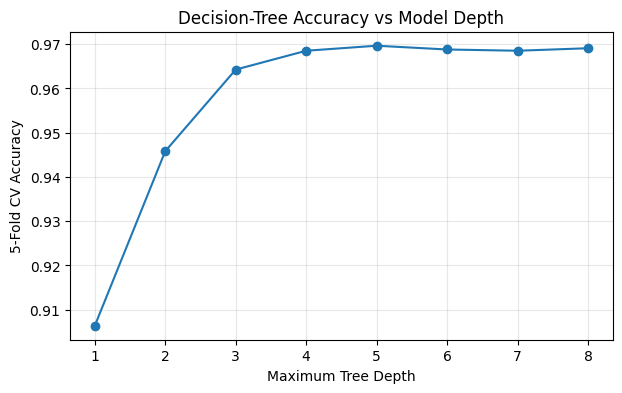

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.plot(
    d1_results["Depth"],
    d1_results["Accuracy"],
    marker="o"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("5-Fold CV Accuracy")
plt.title("Decision-Tree Accuracy vs Model Depth")
plt.xticks(range(1, 9))
plt.grid(True, alpha=0.3)

plt.show()

In [ ]:
print(df.columns.tolist())

['Age', 'No of Pregnancy', 'Gestation in previous Pregnancy', 'BMI', 'HDL', 'Family History', 'unexplained prenetal loss', 'Large Child or Birth Default', 'PCOS', 'Sys BP', 'Dia BP', 'Hemoglobin', 'Sedentary Lifestyle', 'Prediabetes', 'Class Label(GDM /Non GDM)']


In [ ]:
print([name for name in globals().keys()
       if "df" in name.lower() or "data" in name.lower()])

['df', 'stats_df', 'minimal_results_df']


In [ ]:
print([name for name in globals().keys()
       if any(x in name.lower() for x in
              ["pred", "prob", "proba", "y_true", "y_pred", "oof"])])

['cross_val_predict', 'oof_probs', 'prob', 'ensemble_prob', 'prob_true', 'prob_pred', 'platt_prob', 'isotonic_prob', 'pred']


In [ ]:
print("oof_probs:", type(oof_probs), getattr(oof_probs, "shape", None))
print("prob:", type(prob), getattr(prob, "shape", None))
print("ensemble_prob:", type(ensemble_prob), getattr(ensemble_prob, "shape", None))
print("pred:", type(pred), getattr(pred, "shape", None))

oof_probs: <class 'dict'> None
prob: <class 'numpy.ndarray'> (705,)
ensemble_prob: <class 'numpy.ndarray'> (3525,)
pred: <class 'numpy.ndarray'> (705,)


In [ ]:
print("df shape:", df.shape)
print("Target counts:")
print(df["Class Label(GDM /Non GDM)"].value_counts())

df shape: (3525, 15)
Target counts:
Class Label(GDM /Non GDM)
0    2153
1    1372
Name: count, dtype: int64


In [ ]:
print("OOF probability models:")
print(oof_probs.keys())

for k, v in oof_probs.items():
    print(k, type(v), getattr(v, "shape", None))

OOF probability models:
dict_keys(['RF', 'XGB', 'SVM', 'KNN'])
RF <class 'numpy.ndarray'> (3525,)
XGB <class 'numpy.ndarray'> (3525,)
SVM <class 'numpy.ndarray'> (3525,)
KNN <class 'numpy.ndarray'> (3525,)


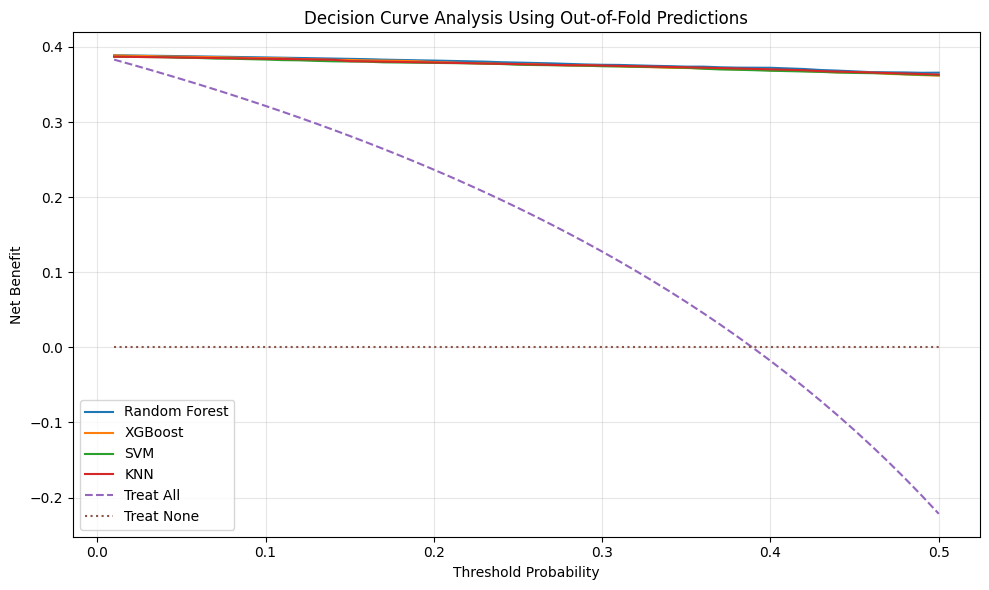

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. True labels
# --------------------------------------------------
y_true = df["Class Label(GDM /Non GDM)"].astype(int).values

# --------------------------------------------------
# 2. Decision Curve Analysis function
# --------------------------------------------------
def net_benefit(y_true, prob, thresholds):

    n = len(y_true)
    results = []

    for pt in thresholds:

        pred_positive = prob >= pt

        TP = np.sum((pred_positive == 1) & (y_true == 1))
        FP = np.sum((pred_positive == 1) & (y_true == 0))

        if pt == 0:
            nb = TP / n
        else:
            nb = (TP / n) - (FP / n) * (pt / (1 - pt))

        results.append(nb)

    return np.array(results)


# --------------------------------------------------
# 3. Threshold range
# --------------------------------------------------
thresholds = np.arange(0.01, 0.51, 0.01)

# --------------------------------------------------
# 4. Model net benefit
# --------------------------------------------------
nb_rf = net_benefit(y_true, oof_probs["RF"], thresholds)
nb_xgb = net_benefit(y_true, oof_probs["XGB"], thresholds)
nb_svm = net_benefit(y_true, oof_probs["SVM"], thresholds)
nb_knn = net_benefit(y_true, oof_probs["KNN"], thresholds)

# --------------------------------------------------
# 5. Treat-all and treat-none
# --------------------------------------------------
prevalence = np.mean(y_true)

nb_all = prevalence - (1 - prevalence) * (
    thresholds / (1 - thresholds)
)

nb_none = np.zeros_like(thresholds)

# --------------------------------------------------
# 6. Plot
# --------------------------------------------------
plt.figure(figsize=(10, 6))

plt.plot(thresholds, nb_rf, label="Random Forest")
plt.plot(thresholds, nb_xgb, label="XGBoost")
plt.plot(thresholds, nb_svm, label="SVM")
plt.plot(thresholds, nb_knn, label="KNN")

plt.plot(thresholds, nb_all, "--", label="Treat All")
plt.plot(thresholds, nb_none, ":", label="Treat None")

plt.xlabel("Threshold Probability")
plt.ylabel("Net Benefit")
plt.title("Decision Curve Analysis Using Out-of-Fold Predictions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
dca_table = pd.DataFrame({
    "Threshold": thresholds,
    "RF": nb_rf,
    "XGB": nb_xgb,
    "SVM": nb_svm,
    "KNN": nb_knn,
    "Treat_All": nb_all,
    "Treat_None": nb_none
})

print(dca_table.round(4).to_string(index=False))

 Threshold     RF    XGB    SVM    KNN  Treat_All  Treat_None
      0.01 0.3888 0.3886 0.3868 0.3870     0.3831         0.0
      0.02 0.3886 0.3881 0.3867 0.3867     0.3768         0.0
      0.03 0.3883 0.3878 0.3865 0.3864     0.3703         0.0
      0.04 0.3880 0.3872 0.3863 0.3861     0.3638         0.0
      0.05 0.3877 0.3869 0.3854 0.3858     0.3571         0.0
      0.06 0.3874 0.3866 0.3852 0.3855     0.3502         0.0
      0.07 0.3870 0.3863 0.3844 0.3852     0.3432         0.0
      0.08 0.3867 0.3858 0.3842 0.3849     0.3361         0.0
      0.09 0.3863 0.3852 0.3837 0.3846     0.3288         0.0
      0.10 0.3860 0.3850 0.3831 0.3842     0.3214         0.0
      0.11 0.3856 0.3848 0.3824 0.3839     0.3137         0.0
      0.12 0.3852 0.3839 0.3821 0.3836     0.3059         0.0
      0.13 0.3849 0.3833 0.3813 0.3832     0.2980         0.0
      0.14 0.3845 0.3828 0.3808 0.3828     0.2898         0.0
      0.15 0.3841 0.3826 0.3805 0.3810     0.2814         0.0
      0.

In [ ]:
#B1 — Clinical feature baseline
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

# --------------------------------------------------
# 1. Target
# --------------------------------------------------
target = "Class Label(GDM /Non GDM)"
y = df[target].astype(int)

# --------------------------------------------------
# 2. Clinically motivated feature set
# --------------------------------------------------
clinical_features = [
    "Age",
    "No of Pregnancy",
    "Gestation in previous Pregnancy",
    "BMI",
    "Family History",
    "PCOS",
    "Sys BP",
    "Dia BP",
    "Prediabetes"
]

# --------------------------------------------------
# 3. MMCFS feature set
# --------------------------------------------------
mmcfs_features = [
    "Age",
    "Gestation in previous Pregnancy",
    "BMI",
    "HDL",
    "Family History",
    "unexplained prenetal loss",
    "Large Child or Birth Default",
    "PCOS",
    "Sys BP",
    "Sedentary Lifestyle"
]

# --------------------------------------------------
# 4. Evaluation function
# --------------------------------------------------
def evaluate_feature_set(features, name):

    X = df[features].copy()

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    accuracies = []
    aucs = []

    for train_idx, test_idx in cv.split(X, y):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        model = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("rf", RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            ))
        ])

        model.fit(X_train, y_train)

        prob = model.predict_proba(X_test)[:, 1]
        pred = (prob >= 0.5).astype(int)

        accuracies.append(
            accuracy_score(y_test, pred)
        )

        aucs.append(
            roc_auc_score(y_test, prob)
        )

    return {
        "Model": name,
        "Features": len(features),
        "Accuracy": np.mean(accuracies),
        "Accuracy_SD": np.std(accuracies, ddof=1),
        "ROC_AUC": np.mean(aucs),
        "AUC_SD": np.std(aucs, ddof=1)
    }


# --------------------------------------------------
# 5. Run B1
# --------------------------------------------------
clinical_result = evaluate_feature_set(
    clinical_features,
    "Clinical Baseline"
)

mmcfs_result = evaluate_feature_set(
    mmcfs_features,
    "MMCFS"
)

# --------------------------------------------------
# 6. Results
# --------------------------------------------------
b1_results = pd.DataFrame([
    clinical_result,
    mmcfs_result
])

print("\nB1 — Clinical Baseline vs MMCFS")
print(b1_results.round(4).to_string(index=False))


B1 — Clinical Baseline vs MMCFS
            Model  Features  Accuracy  Accuracy_SD  ROC_AUC  AUC_SD
Clinical Baseline         9    0.9725       0.0033   0.9981  0.0011
            MMCFS        10    0.9725       0.0037   0.9984  0.0004


In [ ]:
print("Variables related to evaluation:")
print([
    name for name in globals()
    if any(x in name.lower() for x in [
        "fold",
        "accuracy",
        "auc",
        "pred",
        "prob",
        "y_true",
        "y_pred"
    ])
])

Variables related to evaluation:
['StratifiedKFold', 'accuracy_score', 'roc_auc_score', 'cross_val_predict', 'oof_probs', 'auc_scores', 'prob', 'auc', 'total_auc', 'ensemble_prob', 'ensemble_auc', 'prob_true', 'prob_pred', 'platt_prob', 'isotonic_prob', 'aucs', 'pred', 'RepeatedStratifiedKFold', 'fold_sel', 'rf_auc', 'y_true']


In [ ]:
#McNemar
from statsmodels.stats.contingency_tables import mcnemar
import numpy as np
import pandas as pd

y_true = df["Class Label(GDM /Non GDM)"].astype(int).values

# --------------------------------------------------
# Convert existing OOF probabilities to predictions
# --------------------------------------------------
oof_pred = {
    "RF": (oof_probs["RF"] >= 0.5).astype(int),
    "XGB": (oof_probs["XGB"] >= 0.5).astype(int),
    "SVM": (oof_probs["SVM"] >= 0.5).astype(int),
    "KNN": (oof_probs["KNN"] >= 0.5).astype(int)
}

# --------------------------------------------------
# McNemar pairwise tests
# --------------------------------------------------
models = list(oof_pred.keys())
results = []

for i in range(len(models)):
    for j in range(i + 1, len(models)):

        m1 = models[i]
        m2 = models[j]

        p1 = oof_pred[m1]
        p2 = oof_pred[m2]

        table = np.zeros((2, 2), dtype=int)

        for a, b in zip(p1 == y_true, p2 == y_true):
            table[int(a), int(b)] += 1

        test = mcnemar(table, exact=False, correction=True)

        results.append({
            "Comparison": f"{m1} vs {m2}",
            "b": table[0, 1],
            "c": table[1, 0],
            "Chi2": test.statistic,
            "p_value": test.pvalue
        })

mcnemar_results = pd.DataFrame(results)

print("\nMcNemar Test Results")
print(mcnemar_results.round(4).to_string(index=False))


McNemar Test Results
Comparison  b  c   Chi2  p_value
 RF vs XGB  7 21 6.0357   0.0140
 RF vs SVM 18 30 2.5208   0.1124
 RF vs KNN 26 35 1.0492   0.3057
XGB vs SVM 25 23 0.0208   0.8852
XGB vs KNN 32 27 0.2712   0.6025
SVM vs KNN 22 19 0.0976   0.7548


In [ ]:
#Wilcoxon + Nadeau–Bengio
print("rf_auc:", type(rf_auc), np.shape(rf_auc))
print("auc_scores:", type(auc_scores), np.shape(auc_scores))

if isinstance(rf_auc, (list, np.ndarray)):
    print("rf_auc values:", rf_auc)

if isinstance(auc_scores, (list, np.ndarray)):
    print("auc_scores values:", auc_scores)

rf_auc: <class 'function'> ()
auc_scores: <class 'dict'> ()


In [ ]:
print("auc_scores keys:")
print(auc_scores.keys())

for k, v in auc_scores.items():
    print("\n", k)
    print("type:", type(v))
    print("shape:", np.shape(v))
    print("values:", v)

auc_scores keys:
dict_keys(['RF', 'XGB', 'SVM', 'KNN'])

 RF
type: <class 'numpy.float64'>
shape: ()
values: 0.998416339530305

 XGB
type: <class 'numpy.float64'>
shape: ()
values: 0.9973394639522586

 SVM
type: <class 'numpy.float64'>
shape: ()
values: 0.9960818113988346

 KNN
type: <class 'numpy.float64'>
shape: ()
values: 0.9924129528395527


In [ ]:
id_candidates = [
    name for name in globals()
    if any(x in name.lower() for x in [
        "fold_auc",
        "fold_auc_scores",
        "outer_auc",
        "outer_scores",
        "rf_fold",
        "xgb_fold",
        "svm_fold",
        "knn_fold",
        "auc_list",
        "auc_history",
        "fold_results"
    ])
]

print(id_candidates)

[]


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score

# --------------------------------------------------
# Existing OOF probabilities
# --------------------------------------------------
y_true = df["Class Label(GDM /Non GDM)"].astype(int).values

# --------------------------------------------------
# Soft-voting ensemble
# --------------------------------------------------
ensemble_prob_calc = (
    oof_probs["RF"]
    + oof_probs["XGB"]
    + oof_probs["SVM"]
    + oof_probs["KNN"]
) / 4

# --------------------------------------------------
# Youden J threshold
# J = Sensitivity + Specificity - 1
# --------------------------------------------------
fpr, tpr, thresholds = roc_curve(
    y_true,
    ensemble_prob_calc
)

youden_j = tpr - fpr

# Ignore infinite threshold
valid = np.isfinite(thresholds)

best_idx = np.argmax(youden_j[valid])

valid_thresholds = thresholds[valid]
valid_tpr = tpr[valid]
valid_fpr = fpr[valid]
valid_j = youden_j[valid]

youden_threshold = valid_thresholds[best_idx]
sensitivity = valid_tpr[best_idx]
specificity = 1 - valid_fpr[best_idx]

# --------------------------------------------------
# Classification at Youden threshold
# --------------------------------------------------
ensemble_pred = (
    ensemble_prob_calc >= youden_threshold
).astype(int)

accuracy = accuracy_score(
    y_true,
    ensemble_pred
)

auc = roc_auc_score(
    y_true,
    ensemble_prob_calc
)

# --------------------------------------------------
# Results
# --------------------------------------------------
print("Soft-Voting Ensemble + Youden J")
print("--------------------------------")
print(f"AUC:          {auc:.4f}")
print(f"Threshold:    {youden_threshold:.4f}")
print(f"Sensitivity:  {sensitivity:.4f}")
print(f"Specificity:  {specificity:.4f}")
print(f"Accuracy:     {accuracy:.4f}")
print(f"Youden J:     {valid_j[best_idx]:.4f}")

Soft-Voting Ensemble + Youden J
--------------------------------
AUC:          0.9983
Threshold:    0.4104
Sensitivity:  0.9869
Specificity:  0.9693
Accuracy:     0.9762
Youden J:     0.9562


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

cv = StratifiedKFold(5, shuffle=True, random_state=42)
def run(cols):
    p = make_pipeline(SimpleImputer(strategy="median"),
                      RandomForestClassifier(200, random_state=42))
    acc = cross_val_score(p, X[cols], y, cv=cv, scoring="accuracy")
    auc = cross_val_score(p, X[cols], y, cv=cv, scoring="roc_auc")
    return acc.mean(), auc.mean()

drop = ["BMI", "HDL", "Systolic BP"]          # use your exact column names
print("all 14:", run(list(X.columns)))
print("drop 3:", run([c for c in X.columns if c not in drop]))

all 14: (np.float64(0.973900709219858), np.float64(0.9984216220346347))
drop 3: (np.float64(0.9719148936170212), np.float64(0.9983869698381598))


In [ ]:
from collections import Counter

# fold_features = [list_of_features_fold1, ..., list_of_features_fold5]
counts = Counter(f for fold in fold_features for f in fold)
for f, c in counts.most_common():
    print(f, c)

sc10 = [f for f, c in counts.items() if c >= 4]
print(len(sc10), sc10)

NameError: name 'fold_features' is not defined